In [4]:
import os
import json
from glob import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics.models.sam import SAM3Predictor, SAM3SemanticPredictor

PROMPT = "box"            # "text", "box", "interior", or "vertices"
TEXT_PROMPT = ["greenhouse"]
N_IMAGES = 30              # set to None to run the whole dataset

overrides = {
    "conf": 0.25,
    "task": "segment",
    "mode": "predict",
    "model": "sam3.1_multiplex.pt",  # or "sam3.pt"
    "quantize": 16,                  # FP16
    "imgsz": 1008,                   # must be a multiple of 14 (SAM 3 native size)
    "save": False,
    "verbose": False,
}

# Text prompts -> semantic predictor (finds every instance of a concept).
# Box / point prompts -> interactive predictor (segments exactly the prompted object).
PredictorCls = SAM3SemanticPredictor if PROMPT == "text" else SAM3Predictor
predictor = PredictorCls(overrides=overrides)

In [5]:
def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))

def show_box(box, ax):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                               edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

def iou(gt, pred):
    gt, pred = gt.astype(bool), pred.astype(bool)
    union = np.logical_or(gt, pred).sum()
    return np.logical_and(gt, pred).sum() / union if union else 1.0

def interior_point(poly, H, W):
    """A point guaranteed to be inside the polygon (deepest pixel)."""
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [poly.astype(np.int32)], 1)
    dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    y, x = np.unravel_index(dist.argmax(), dist.shape)
    return [float(x), float(y)]

def union_mask(results, H, W):
    """Merge all instance masks from an Ultralytics Results list into one HxW bool mask."""
    out = np.zeros((H, W), bool)
    for res in results:
        if res.masks is None:
            continue
        m = res.masks.data.cpu().numpy() > 0.5          # (N, h, w)
        for inst in m:
            if inst.shape != (H, W):
                inst = cv2.resize(inst.astype(np.uint8), (W, H),
                                  interpolation=cv2.INTER_NEAREST).astype(bool)
            out |= inst
    return out

  0%|          | 0/30 [00:00<?, ?it/s]

Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)
1  IoU: 0.934


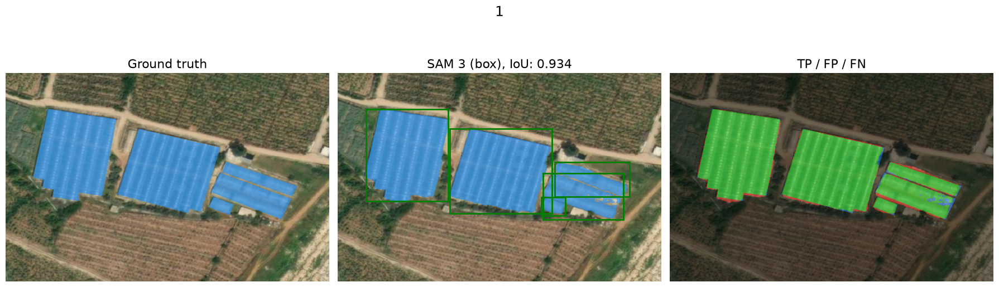

  3%|▎         | 1/30 [00:06<03:02,  6.30s/it]

10  IoU: 0.967


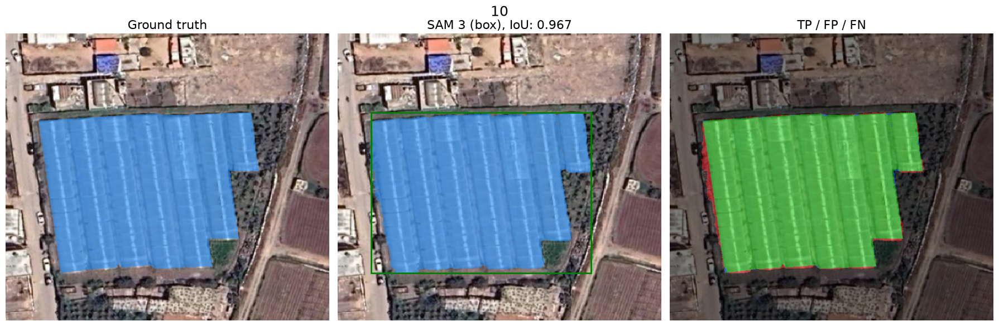

  7%|▋         | 2/30 [00:07<01:26,  3.09s/it]

100  IoU: 0.939


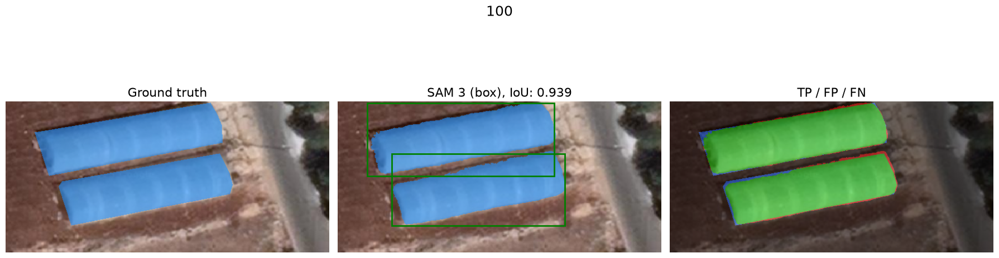

 10%|█         | 3/30 [00:07<00:52,  1.94s/it]

101  IoU: 0.956


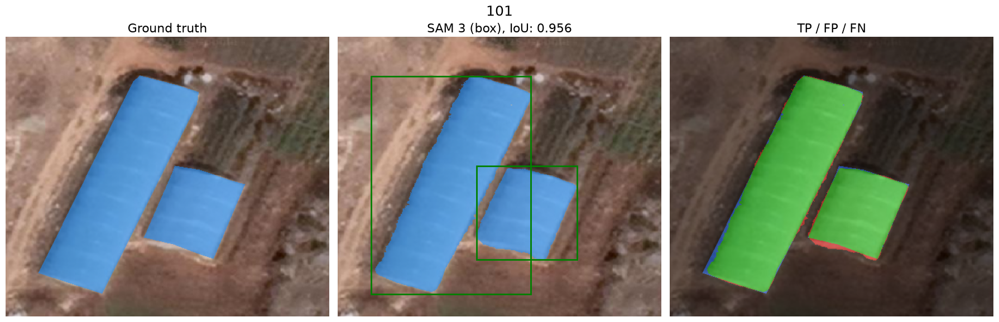

 13%|█▎        | 4/30 [00:08<00:38,  1.46s/it]

102  IoU: 0.805


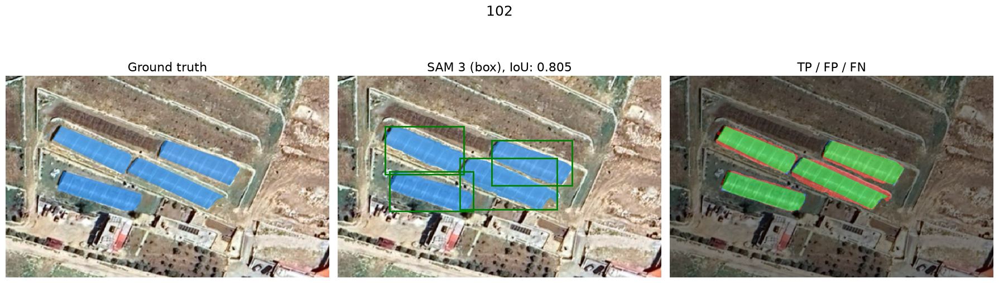

 17%|█▋        | 5/30 [00:09<00:29,  1.19s/it]

103  IoU: 0.831


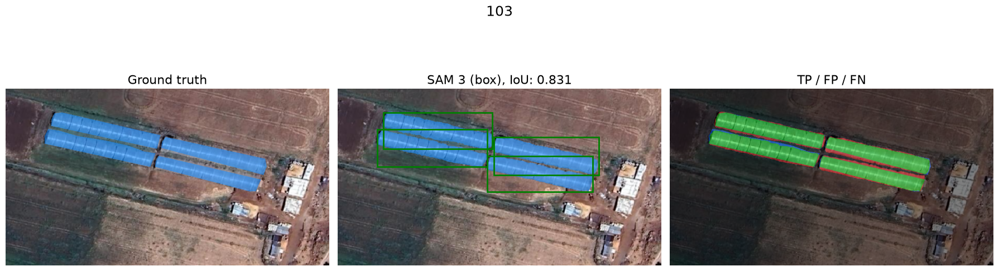

 20%|██        | 6/30 [00:09<00:24,  1.04s/it]

104  IoU: 0.877


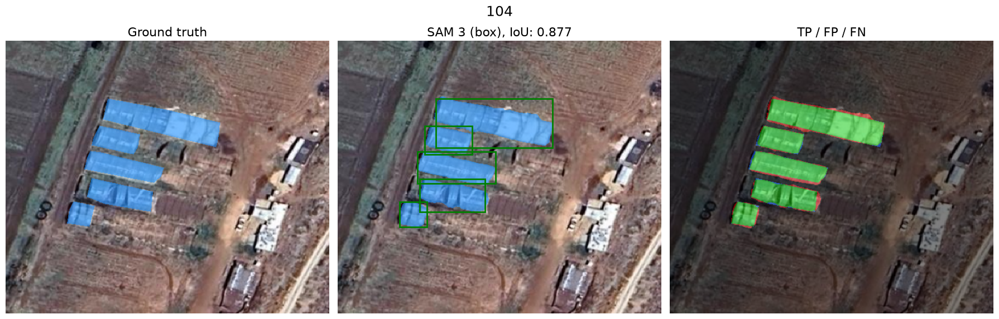

 23%|██▎       | 7/30 [00:10<00:21,  1.06it/s]

105  IoU: 0.819


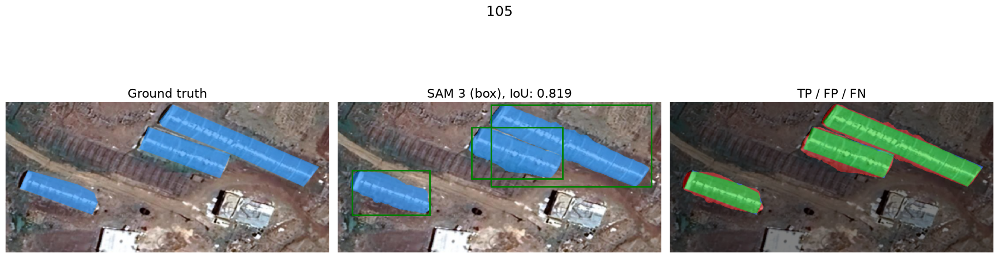

 27%|██▋       | 8/30 [00:11<00:19,  1.13it/s]

106  IoU: 0.863


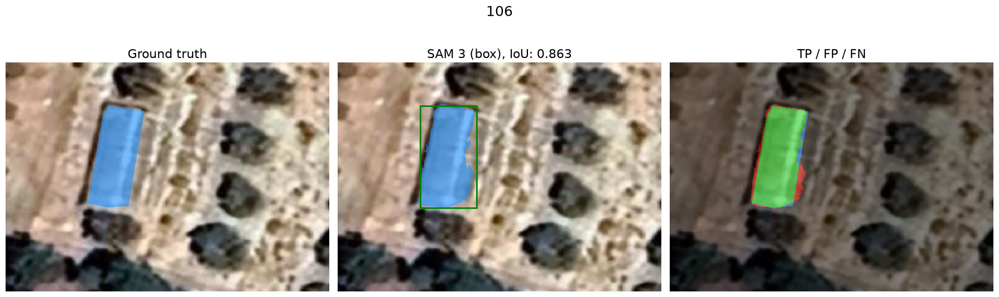

 30%|███       | 9/30 [00:12<00:17,  1.21it/s]

107  IoU: 0.918


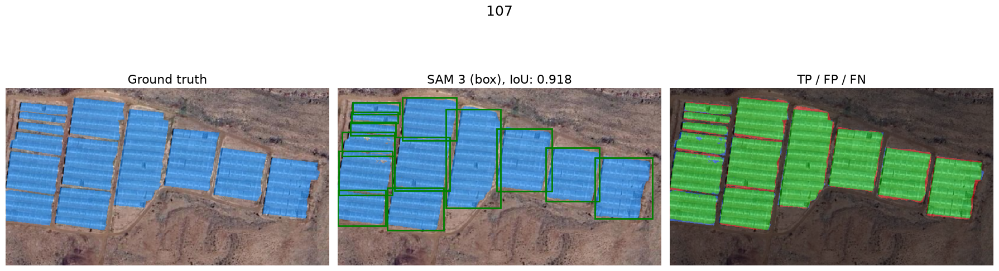

 33%|███▎      | 10/30 [00:12<00:16,  1.24it/s]

108  IoU: 0.969


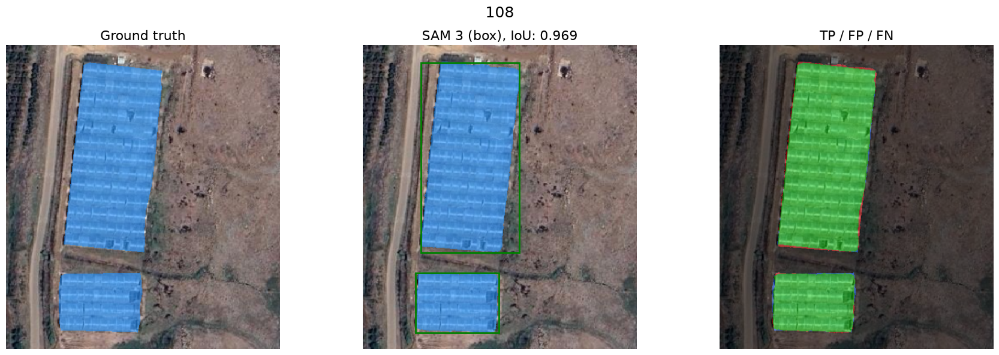

 37%|███▋      | 11/30 [00:13<00:14,  1.31it/s]

109  IoU: 0.908


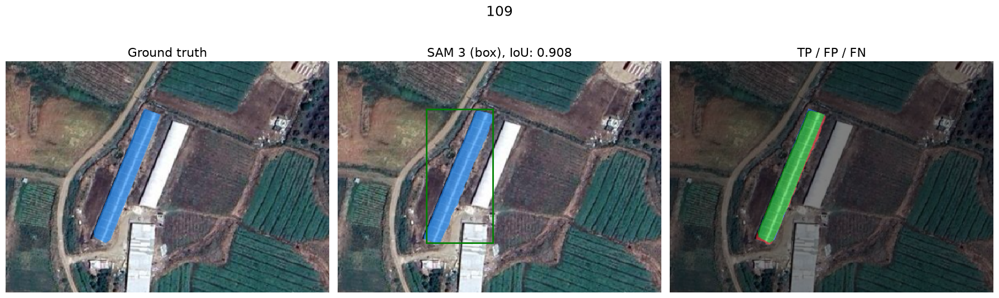

 40%|████      | 12/30 [00:14<00:13,  1.36it/s]

11  IoU: 0.954


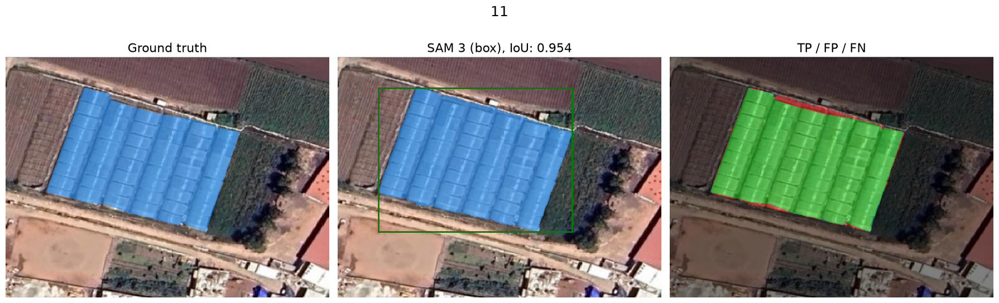

 43%|████▎     | 13/30 [00:14<00:12,  1.35it/s]

110  IoU: 0.885


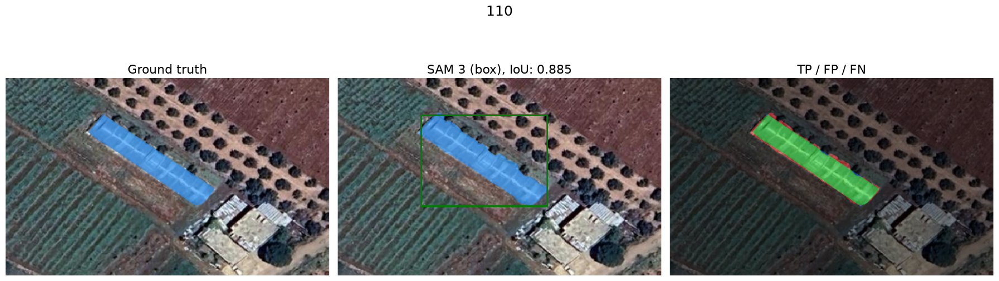

 47%|████▋     | 14/30 [00:15<00:11,  1.40it/s]

111  IoU: 0.656


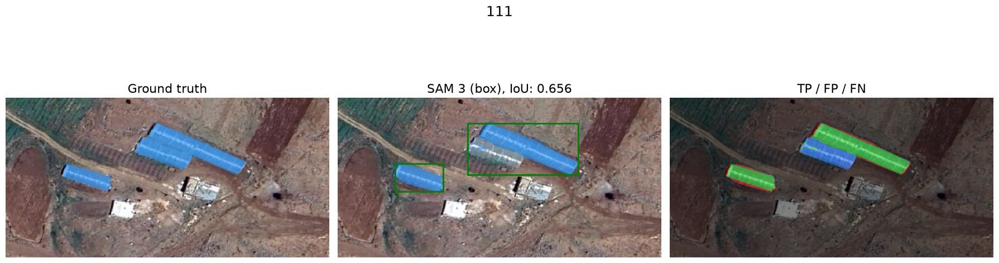

 50%|█████     | 15/30 [00:16<00:10,  1.42it/s]

112  IoU: 0.829


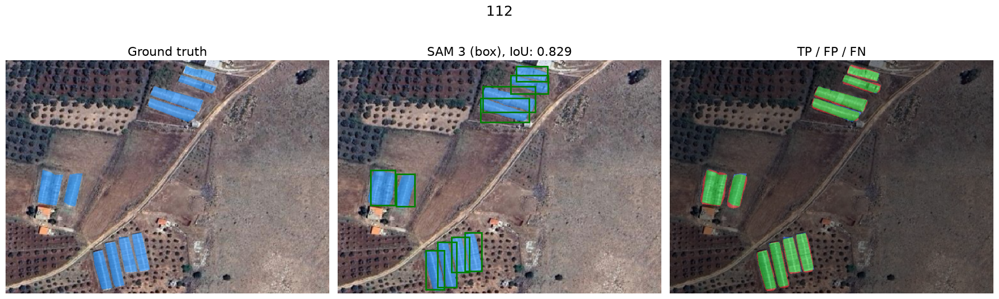

 53%|█████▎    | 16/30 [00:17<00:10,  1.35it/s]

113  IoU: 0.900


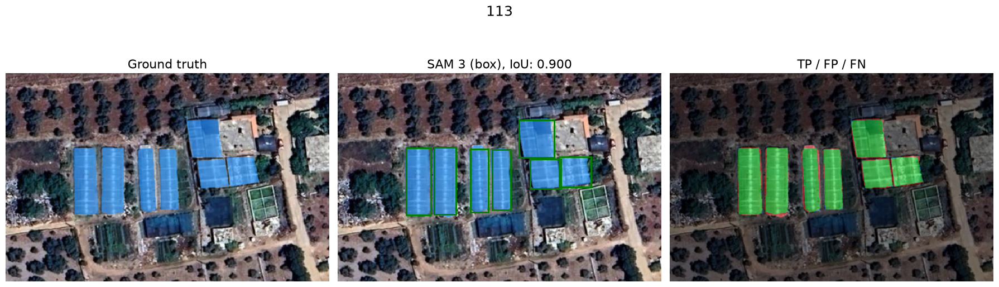

 57%|█████▋    | 17/30 [00:17<00:09,  1.34it/s]

114  IoU: 0.916


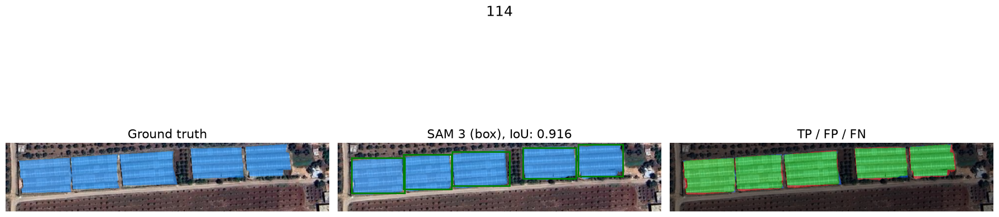

 60%|██████    | 18/30 [00:18<00:08,  1.45it/s]

115  IoU: 0.932


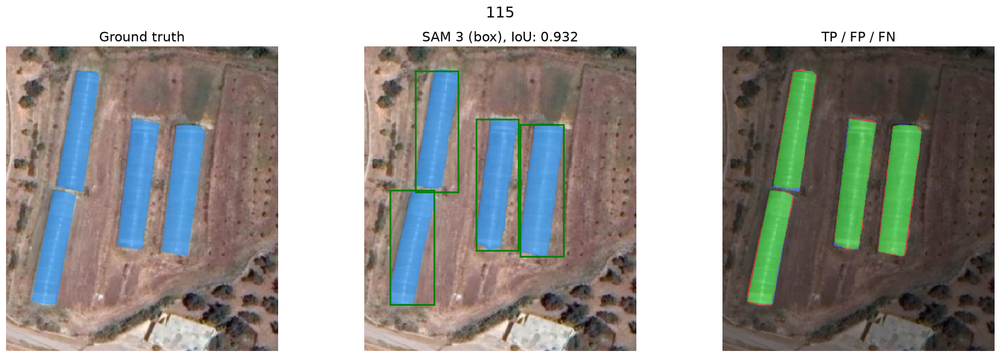

 63%|██████▎   | 19/30 [00:19<00:07,  1.43it/s]

116  IoU: 0.792


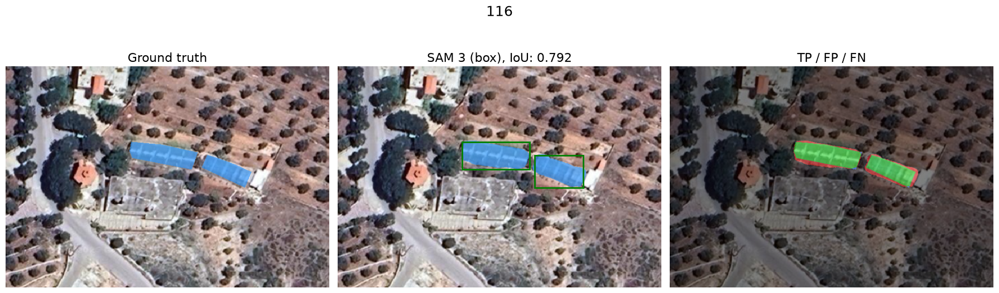

 67%|██████▋   | 20/30 [00:20<00:07,  1.31it/s]

117  IoU: 0.967


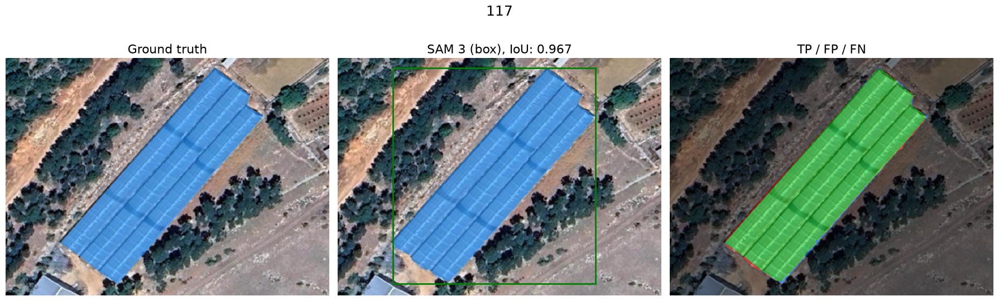

 70%|███████   | 21/30 [00:20<00:06,  1.30it/s]

118  IoU: 0.937


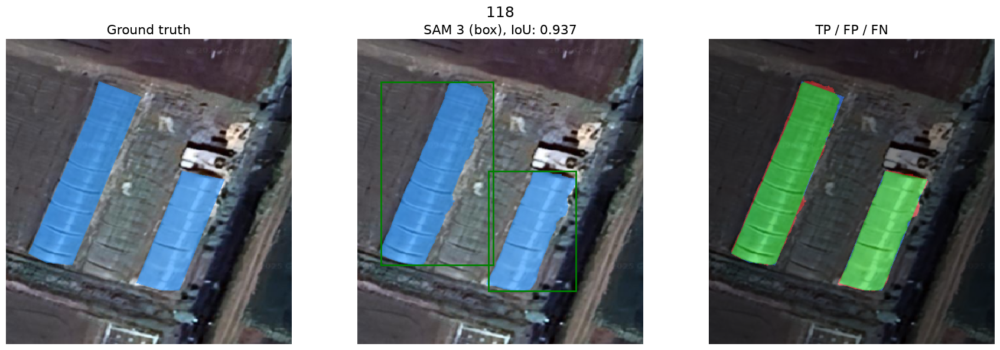

 73%|███████▎  | 22/30 [00:21<00:06,  1.31it/s]

119  IoU: 0.903


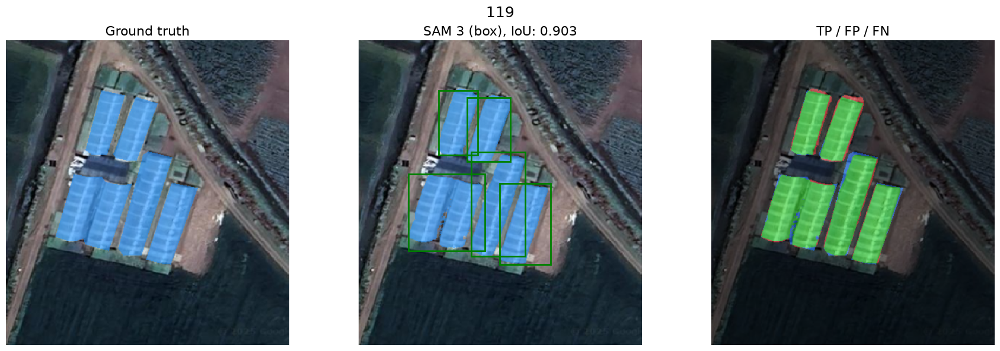

 77%|███████▋  | 23/30 [00:22<00:05,  1.33it/s]

12  IoU: 0.908


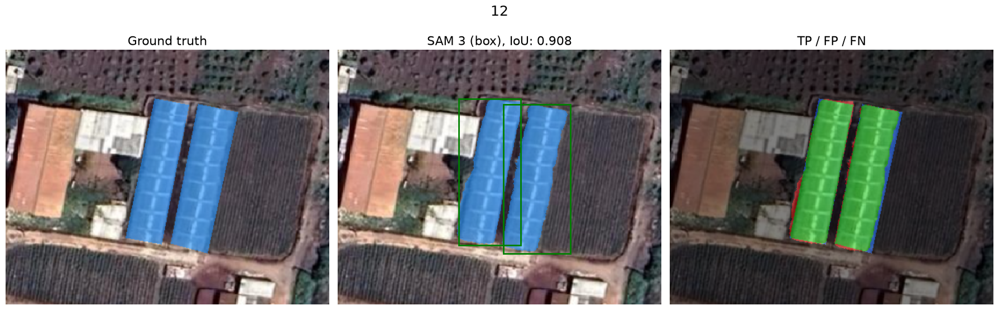

 80%|████████  | 24/30 [00:23<00:04,  1.34it/s]

120  IoU: 0.887


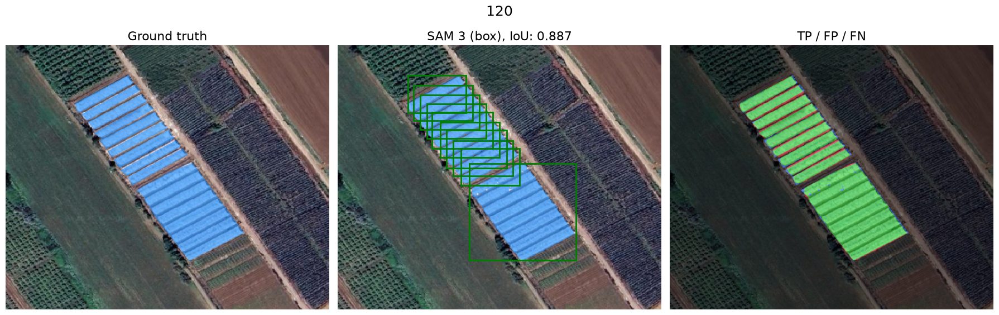

 83%|████████▎ | 25/30 [00:23<00:03,  1.30it/s]

121  IoU: 0.901


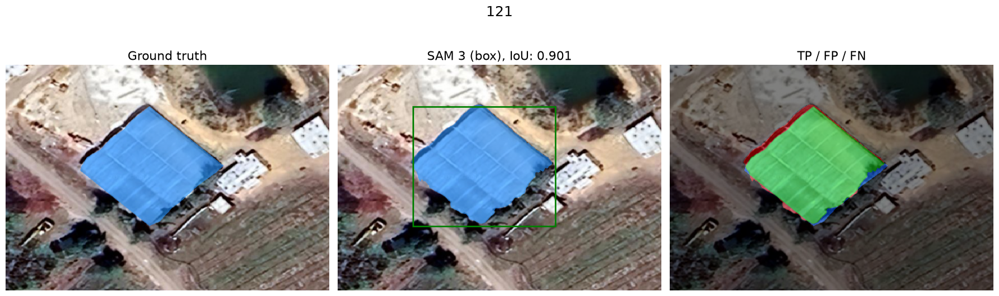

 87%|████████▋ | 26/30 [00:24<00:03,  1.28it/s]

122  IoU: 0.875


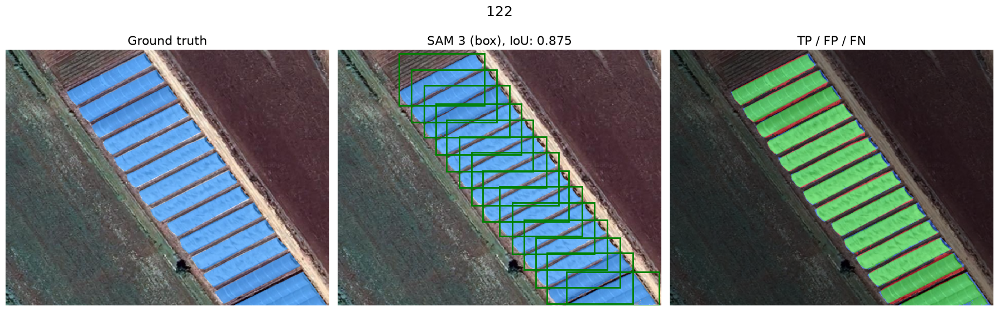

 90%|█████████ | 27/30 [00:25<00:02,  1.24it/s]

123  IoU: 0.943


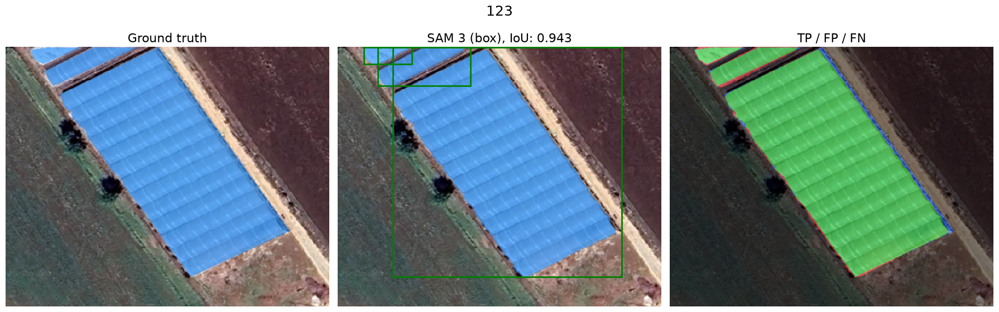

 93%|█████████▎| 28/30 [00:26<00:01,  1.27it/s]

124  IoU: 0.854


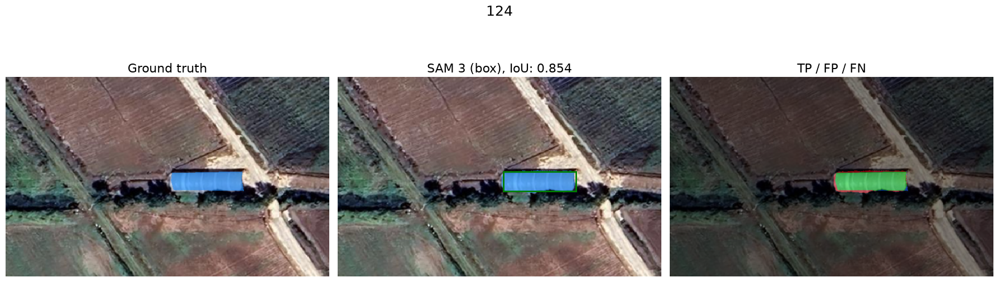

 97%|█████████▋| 29/30 [00:26<00:00,  1.32it/s]

125  IoU: 0.912


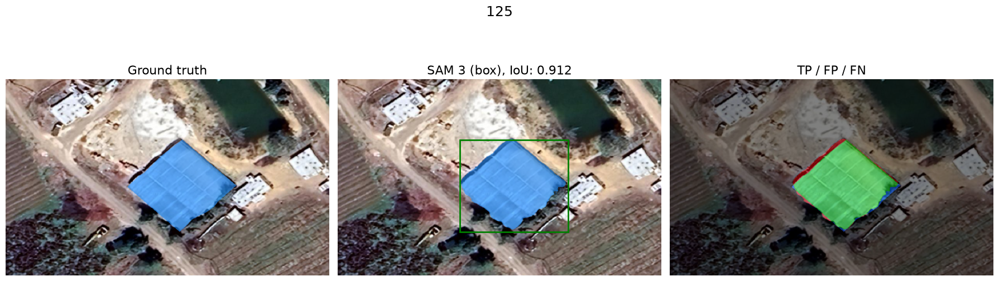

100%|██████████| 30/30 [00:27<00:00,  1.08it/s]


Mean IoU over 30 images (box prompt): 0.891


In [6]:
images = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
masks  = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'

img_paths = sorted(glob(os.path.join(images, '*.png')))[:N_IMAGES]
all_ious = []

for img_path in tqdm(img_paths):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    mask_path = os.path.join(masks, stem + '.png')      # pair by name, not by glob order
    json_path = os.path.join(images, stem + '.json')
    if not (os.path.exists(mask_path) and os.path.exists(json_path)):
        print(f"skipping {stem}: missing mask or json")
        continue

    image_bgr = cv2.imread(img_path)                     # Ultralytics expects BGR arrays
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)   # RGB only for plotting
    gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 0
    H, W = image.shape[:2]

    with open(json_path) as fh:
        ann = json.load(fh)
    polygons = [np.array(s['points'], dtype=np.float32).reshape(-1, 2) for s in ann['shapes']]

    predictor.set_image(image_bgr)
    boxes = [[*map(float, p.min(0)), *map(float, p.max(0))] for p in polygons]

    if PROMPT == "text":
        pred = union_mask(predictor(text=TEXT_PROMPT), H, W)
    elif not polygons:
        pred = np.zeros((H, W), bool)
    elif PROMPT == "box":
        pred = union_mask(predictor(bboxes=boxes), H, W)          # one call, all boxes
    elif PROMPT == "interior":
        pts = [interior_point(p, H, W) for p in polygons]         # one point per object
        pred = union_mask(predictor(points=pts, labels=[1] * len(pts)), H, W)
    elif PROMPT == "vertices":
        pred = np.zeros((H, W), bool)
        for p in polygons:                                        # many points, one object
            pred |= union_mask(predictor(points=[p.tolist()], labels=[[1] * len(p)]), H, W)
    else:
        raise ValueError(f"unknown PROMPT {PROMPT!r}")

    score = iou(gt, pred)
    all_ious.append(score)
    print(f"{stem}  IoU: {score:.3f}")

    # Ground truth | prediction | errors (green = TP, red = FP, blue = FN)
    err = np.zeros((H, W, 3), np.uint8)
    err[gt & pred] = (0, 200, 0)
    err[~gt & pred] = (220, 0, 0)
    err[gt & ~pred] = (0, 90, 255)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(image); show_mask(gt, axes[0]); axes[0].set_title("Ground truth", fontsize=16)
    axes[1].imshow(image); show_mask(pred, axes[1])
    if PROMPT == "box":
        for b in boxes:
            show_box(b, axes[1])
    axes[1].set_title(f"SAM 3 ({PROMPT}), IoU: {score:.3f}", fontsize=16)
    axes[2].imshow(image); axes[2].imshow(err, alpha=0.5)
    axes[2].set_title("TP / FP / FN", fontsize=16)
    for ax in axes:
        ax.axis('off')
    fig.suptitle(stem, fontsize=18)
    plt.tight_layout()
    plt.show()

if all_ious:
    print(f"\nMean IoU over {len(all_ious)} images ({PROMPT} prompt): {np.mean(all_ious):.3f}")